In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Project directory
PROJECT_DIR = Path(
    r"C:\India_Vs_West_Indies_T20i_Challenge"
)

# Load cleaned delivery data
CLEAN_FILE = (
    PROJECT_DIR
    / "Data"
    / "Clean"
    / "t20i_ball_by_ball_clean.csv"
)

df = pd.read_csv(CLEAN_FILE)

# Check that the data loaded correctly
print("Dataset shape:", df.shape)
print("Number of matches:", df["MatchDay"].nunique())
print("Number of innings:", df.groupby(
    ["MatchDay", "Innings"]
).ngroups)
print("Number of bowlers:", df["Bowler"].nunique())

display(df.head())

Dataset shape: (959, 24)
Number of matches: 4
Number of innings: 8
Number of bowlers: 17


,Venue,MatchDay,Innings,Batting Team,Bowling Team,Striker,Non-Striker,Bowler,Ball Number,Actual Ball Number,...,Wide,No Ball,Leg Bye,Bye,Wicket,4's,6's,Run_QC_Flag,Extras_QC_Flag,Ball_Number_Label
0,Ekana Cricket Stadium B Ground,1,1,West Indies Cricket Team,India National Cricket team,Shai Hope,Kamil Pooran,Arshdeep Singh,0.1,0.1,...,0,0,0,0,0,0,0,False,False,0.1
1,Ekana Cricket Stadium B Ground,1,1,West Indies Cricket Team,India National Cricket team,Shai Hope,Kamil Pooran,Arshdeep Singh,0.2,0.2,...,0,0,0,0,0,0,0,False,False,0.2
2,Ekana Cricket Stadium B Ground,1,1,West Indies Cricket Team,India National Cricket team,Shai Hope,Kamil Pooran,Arshdeep Singh,0.3,0.3,...,0,0,0,0,0,0,0,False,False,0.3
3,Ekana Cricket Stadium B Ground,1,1,West Indies Cricket Team,India National Cricket team,Shai Hope,Kamil Pooran,Arshdeep Singh,0.4,0.4,...,0,0,0,0,0,1,0,False,False,0.4
4,Ekana Cricket Stadium B Ground,1,1,West Indies Cricket Team,India National Cricket team,Shai Hope,Kamil Pooran,Arshdeep Singh,0.5,0.5,...,0,0,0,0,0,0,0,False,False,0.5


In [2]:
# Ensure extras are treated as numeric values
for col in ["Wide", "No Ball", "Leg Bye", "Bye"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

# Legal deliveries: wides and no-balls do not count
df["Legal_Ball"] = (
    (df["Wide"] == 0) & (df["No Ball"] == 0)
).astype(int)

# Runs charged to the bowler
df["Bowler_Runs_Conceded"] = (
    df["Runs Off The Bat"] + df["Wide"] + df["No Ball"]
)

# Aggregate by match and bowler
match_bowling = (
    df.groupby(
        ["MatchDay", "Bowler", "Bowling Team"],
        as_index=False
    )
    .agg(
        Legal_Balls=("Legal_Ball", "sum"),
        Runs_Conceded=("Bowler_Runs_Conceded", "sum"),
        Wicket_Events=("Wicket", "sum")
    )
)

# Format overs in cricket notation: 4.2 means 4 overs and 2 balls
match_bowling["Overs"] = (
    (match_bowling["Legal_Balls"] // 6).astype(int).astype(str)
    + "."
    + (match_bowling["Legal_Balls"] % 6).astype(int).astype(str)
)

# Economy rate
match_bowling["Economy"] = (
    match_bowling["Runs_Conceded"] * 6
    / match_bowling["Legal_Balls"].replace(0, np.nan)
).round(2)

# Show the results
match_bowling = match_bowling.sort_values(
    ["MatchDay", "Bowling Team", "Economy"],
    ascending=[True, True, True]
).reset_index(drop=True)

display(match_bowling)

,MatchDay,Bowler,Bowling Team,Legal_Balls,Runs_Conceded,Wicket_Events,Overs,Economy
0,1,Naman Dhir,India National Cricket team,24,31,3,4.0,7.75
1,1,Kuldeep Yadav,India National Cricket team,24,33,2,4.0,8.25
2,1,Arshdeep Singh,India National Cricket team,24,34,1,4.0,8.50
3,1,Axar Patel,India National Cricket team,18,26,2,3.0,8.67
4,1,Mayank Yadav,India National Cricket team,25,40,2,4.1,9.60
5,1,Akeal Hosein,West Indies Cricket Team,24,37,1,4.0,9.25
6,1,Roston Chase,West Indies Cricket Team,22,37,1,3.4,10.09
7,1,Shamar Joseph,West Indies Cricket Team,12,23,0,2.0,11.50
8,1,Romario Shepherd,West Indies Cricket Team,12,24,0,2.0,12.00
9,1,Shamar Springer,West Indies Cricket Team,6,12,0,1.0,12.00


In [3]:
# Check that each bowler's match figures are internally consistent

# 1. Recalculate economy
match_bowling["Economy_Check"] = (
    match_bowling["Runs_Conceded"] * 6
    / match_bowling["Legal_Balls"].replace(0, np.nan)
).round(2)

print(
    "Economy mismatches:",
    (
        match_bowling["Economy"]
        != match_bowling["Economy_Check"]
    ).sum()
)

# 2. Check for duplicate bowler-match entries
print(
    "Duplicate bowler-match entries:",
    match_bowling.duplicated(
        subset=["MatchDay", "Bowler", "Bowling Team"]
    ).sum()
)

# 3. Display summary by match
match_totals = (
    match_bowling.groupby("MatchDay", as_index=False)
    .agg(
        Bowlers=("Bowler", "nunique"),
        Legal_Balls=("Legal_Balls", "sum"),
        Runs_Conceded=("Runs_Conceded", "sum"),
        Wicket_Events=("Wicket_Events", "sum")
    )
)

display(match_totals)

Economy mismatches: 0
Duplicate bowler-match entries: 0


,MatchDay,Bowlers,Legal_Balls,Runs_Conceded,Wicket_Events
0,1,11,203,336,12
1,2,13,231,500,9
2,3,11,240,423,17
3,4,12,237,459,12


In [4]:
# Create a bowler-by-match economy comparison table

economy_comparison = match_bowling.pivot_table(
    index=["Bowler", "Bowling Team"],
    columns="MatchDay",
    values="Economy",
    aggfunc="first"
).reset_index()

# Rename match columns
economy_comparison = economy_comparison.rename(
    columns={
        1: "Match_1_Economy",
        2: "Match_2_Economy",
        3: "Match_3_Economy",
        4: "Match_4_Economy"
    }
)

display(
    economy_comparison.sort_values(
        "Bowler"
    ).reset_index(drop=True)
)

MatchDay,Bowler,Bowling Team,Match_1_Economy,Match_2_Economy,Match_3_Economy,Match_4_Economy
0,Akeal Hosein,West Indies Cricket Team,9.25,15.33,NaN,NaN
1,Arshdeep Singh,India National Cricket team,8.50,11.25,11.00,13.00
2,Axar Patel,India National Cricket team,8.67,18.00,11.00,11.25
3,Gudakesh Motie,West Indies Cricket Team,NaN,10.50,9.25,6.50
4,Keemo Paul,West Indies Cricket Team,NaN,NaN,9.50,10.25
5,Kuldeep Yadav,India National Cricket team,8.25,13.25,NaN,NaN
6,Matthew Forde,West Indies Cricket Team,19.50,NaN,NaN,NaN
7,Mayank Yadav,India National Cricket team,9.60,12.00,8.50,13.00
8,Naman Dhir,India National Cricket team,7.75,12.50,13.00,19.00
9,Nitish Reddy,India National Cricket team,NaN,NaN,9.50,13.00


In [5]:
# Aggregate bowling performance across all matches

overall_bowling = (
    match_bowling.groupby(
        ["Bowler", "Bowling Team"],
        as_index=False
    )
    .agg(
        Matches_Bowled=("MatchDay", "nunique"),
        Legal_Balls=("Legal_Balls", "sum"),
        Runs_Conceded=("Runs_Conceded", "sum"),
        Wicket_Events=("Wicket_Events", "sum")
    )
)

# Calculate overall economy from total runs and legal balls
overall_bowling["Overs"] = (
    (overall_bowling["Legal_Balls"] // 6).astype(int).astype(str)
    + "."
    + (overall_bowling["Legal_Balls"] % 6).astype(int).astype(str)
)

overall_bowling["Economy"] = (
    overall_bowling["Runs_Conceded"] * 6
    / overall_bowling["Legal_Balls"].replace(0, np.nan)
).round(2)

# Sort by economy, lowest first
overall_bowling = overall_bowling.sort_values(
    ["Economy", "Legal_Balls"],
    ascending=[True, False]
).reset_index(drop=True)

display(overall_bowling)

,Bowler,Bowling Team,Matches_Bowled,Legal_Balls,Runs_Conceded,Wicket_Events,Overs,Economy
0,Gudakesh Motie,West Indies Cricket Team,3,48,71,4,8.0,8.88
1,Roston Chase,West Indies Cricket Team,4,94,142,6,15.4,9.06
2,Prince Yadav,India National Cricket team,2,48,73,1,8.0,9.12
3,Keemo Paul,West Indies Cricket Team,2,48,79,6,8.0,9.88
4,Mayank Yadav,India National Cricket team,4,91,162,5,15.1,10.68
5,Kuldeep Yadav,India National Cricket team,2,48,86,3,8.0,10.75
6,Arshdeep Singh,India National Cricket team,4,96,175,5,16.0,10.94
7,Naman Dhir,India National Cricket team,4,60,114,5,10.0,11.40
8,Nitish Reddy,India National Cricket team,2,30,58,1,5.0,11.60
9,Akeal Hosein,West Indies Cricket Team,2,42,83,1,7.0,11.86


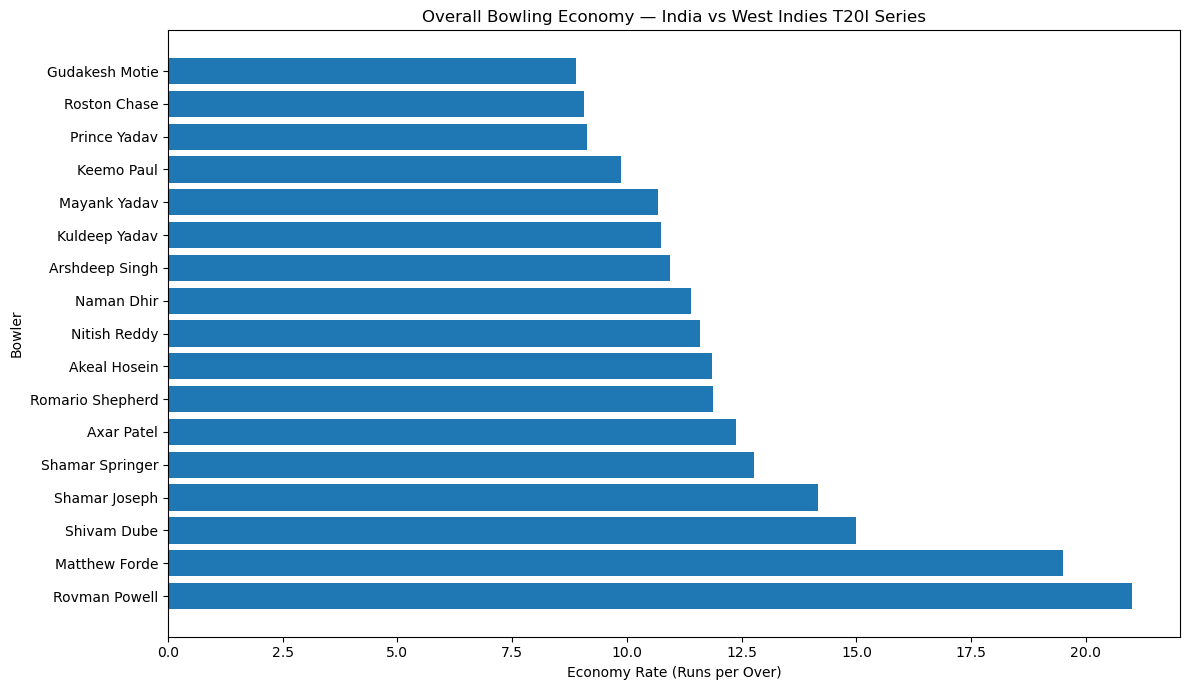

In [6]:
import matplotlib.pyplot as plt

# Sort from lowest to highest economy
economy_chart = overall_bowling.sort_values(
    "Economy", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    economy_chart["Bowler"],
    economy_chart["Economy"]
)

plt.xlabel("Economy Rate (Runs per Over)")
plt.ylabel("Bowler")
plt.title("Overall Bowling Economy — India vs West Indies T20I Series")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

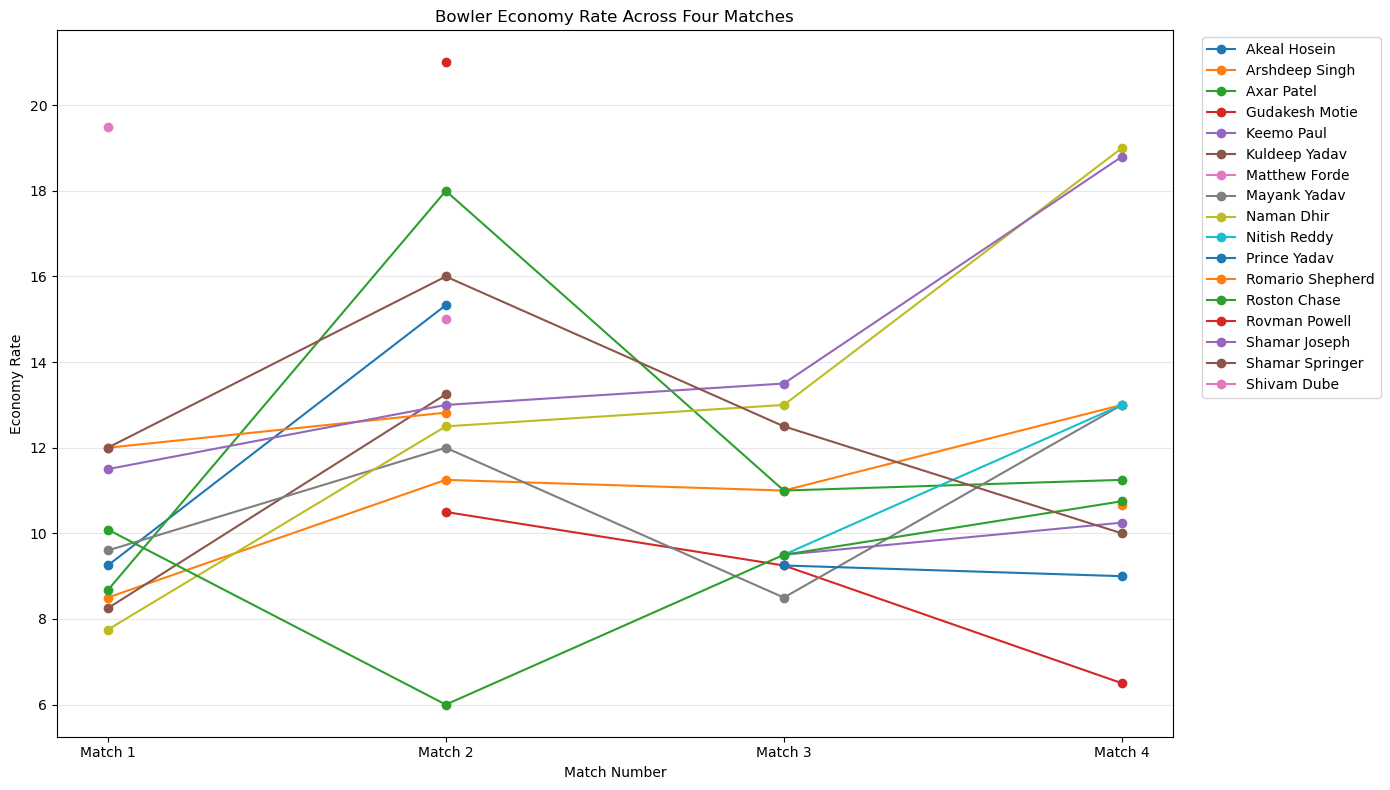

In [7]:
import matplotlib.pyplot as plt

# Create a separate line for each bowler
economy_pivot = match_bowling.pivot_table(
    index="MatchDay",
    columns="Bowler",
    values="Economy",
    aggfunc="first"
)

plt.figure(figsize=(14, 8))

for bowler in economy_pivot.columns:
    plt.plot(
        economy_pivot.index,
        economy_pivot[bowler],
        marker="o",
        label=bowler
    )

plt.xlabel("Match Number")
plt.ylabel("Economy Rate")
plt.title("Bowler Economy Rate Across Four Matches")
plt.xticks([1, 2, 3, 4], ["Match 1", "Match 2", "Match 3", "Match 4"])
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
%pip install adjustText

Note: you may need to restart the kernel to use updated packages.


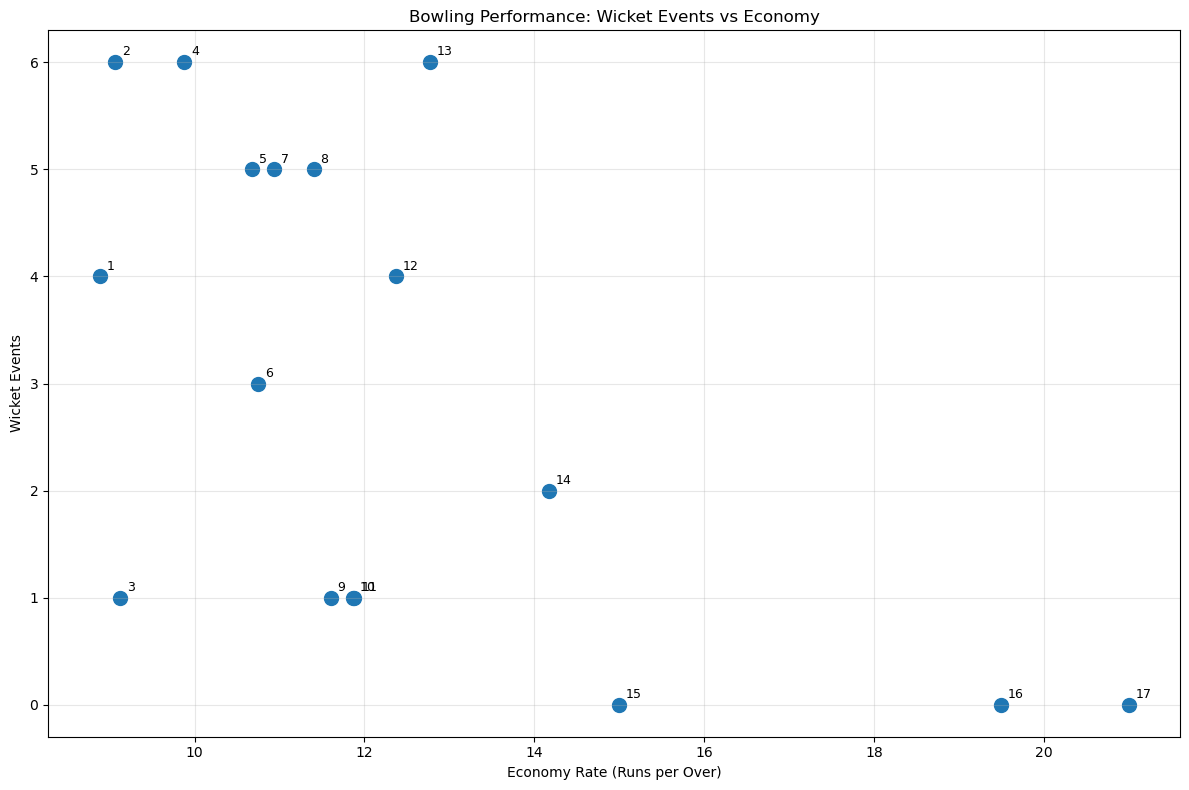

,Bowler_ID,Bowler,Bowling Team,Economy,Wicket_Events,Legal_Balls
0,1,Gudakesh Motie,West Indies Cricket Team,8.88,4,48
1,2,Roston Chase,West Indies Cricket Team,9.06,6,94
2,3,Prince Yadav,India National Cricket team,9.12,1,48
3,4,Keemo Paul,West Indies Cricket Team,9.88,6,48
4,5,Mayank Yadav,India National Cricket team,10.68,5,91
5,6,Kuldeep Yadav,India National Cricket team,10.75,3,48
6,7,Arshdeep Singh,India National Cricket team,10.94,5,96
7,8,Naman Dhir,India National Cricket team,11.40,5,60
8,9,Nitish Reddy,India National Cricket team,11.60,1,30
9,10,Akeal Hosein,West Indies Cricket Team,11.86,1,42


In [12]:
import matplotlib.pyplot as plt

# Sort bowlers by economy
plot_df = overall_bowling.sort_values(
    ["Economy", "Wicket_Events"],
    ascending=[True, False]
).reset_index(drop=True)

# Assign a number to each bowler
plot_df["Bowler_ID"] = range(1, len(plot_df) + 1)

fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(
    plot_df["Economy"],
    plot_df["Wicket_Events"],
    s=100
)

# Display only the numbered IDs beside points
for _, row in plot_df.iterrows():
    ax.annotate(
        str(row["Bowler_ID"]),
        (row["Economy"], row["Wicket_Events"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel("Economy Rate (Runs per Over)")
ax.set_ylabel("Wicket Events")
ax.set_title("Bowling Performance: Wicket Events vs Economy")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Display the ID-to-bowler mapping
display(
    plot_df[
        ["Bowler_ID", "Bowler", "Bowling Team",
         "Economy", "Wicket_Events", "Legal_Balls"]
    ]
)

In [13]:
# Filter bowlers who bowled at least 4 overs
qualified_bowlers = overall_bowling[
    overall_bowling["Legal_Balls"] >= 24
].copy()

# Rank by economy, lowest first
qualified_bowlers = qualified_bowlers.sort_values(
    "Economy",
    ascending=True
).reset_index(drop=True)

qualified_bowlers.insert(
    0,
    "Economy_Rank",
    range(1, len(qualified_bowlers) + 1)
)

display(
    qualified_bowlers[
        [
            "Economy_Rank",
            "Bowler",
            "Bowling Team",
            "Matches_Bowled",
            "Overs",
            "Runs_Conceded",
            "Wicket_Events",
            "Economy"
        ]
    ]
)

,Economy_Rank,Bowler,Bowling Team,Matches_Bowled,Overs,Runs_Conceded,Wicket_Events,Economy
0,1,Gudakesh Motie,West Indies Cricket Team,3,8.0,71,4,8.88
1,2,Roston Chase,West Indies Cricket Team,4,15.4,142,6,9.06
2,3,Prince Yadav,India National Cricket team,2,8.0,73,1,9.12
3,4,Keemo Paul,West Indies Cricket Team,2,8.0,79,6,9.88
4,5,Mayank Yadav,India National Cricket team,4,15.1,162,5,10.68
5,6,Kuldeep Yadav,India National Cricket team,2,8.0,86,3,10.75
6,7,Arshdeep Singh,India National Cricket team,4,16.0,175,5,10.94
7,8,Naman Dhir,India National Cricket team,4,10.0,114,5,11.40
8,9,Nitish Reddy,India National Cricket team,2,5.0,58,1,11.60
9,10,Akeal Hosein,West Indies Cricket Team,2,7.0,83,1,11.86


In [14]:
# Calculate average wicket events per match
bowling_performance = overall_bowling.copy()

bowling_performance["Wicket_Events_Per_Match"] = (
    bowling_performance["Wicket_Events"] /
    bowling_performance["Matches_Bowled"]
).round(2)

# Filter for bowlers with at least 4 overs
bowling_performance = bowling_performance[
    bowling_performance["Legal_Balls"] >= 24
].copy()

# Sort by average wicket events, then economy
bowling_performance = bowling_performance.sort_values(
    ["Wicket_Events_Per_Match", "Economy"],
    ascending=[False, True]
).reset_index(drop=True)

display(
    bowling_performance[
        [
            "Bowler",
            "Bowling Team",
            "Matches_Bowled",
            "Legal_Balls",
            "Wicket_Events",
            "Wicket_Events_Per_Match",
            "Economy"
        ]
    ]
)

,Bowler,Bowling Team,Matches_Bowled,Legal_Balls,Wicket_Events,Wicket_Events_Per_Match,Economy
0,Keemo Paul,West Indies Cricket Team,2,48,6,3.00,9.88
1,Roston Chase,West Indies Cricket Team,4,94,6,1.50,9.06
2,Kuldeep Yadav,India National Cricket team,2,48,3,1.50,10.75
3,Shamar Springer,West Indies Cricket Team,4,78,6,1.50,12.77
4,Gudakesh Motie,West Indies Cricket Team,3,48,4,1.33,8.88
5,Mayank Yadav,India National Cricket team,4,91,5,1.25,10.68
6,Arshdeep Singh,India National Cricket team,4,96,5,1.25,10.94
7,Naman Dhir,India National Cricket team,4,60,5,1.25,11.40
8,Axar Patel,India National Cricket team,4,81,4,1.00,12.37
9,Prince Yadav,India National Cricket team,2,48,1,0.50,9.12


In [15]:
from pathlib import Path

# Create output folders
PROCESSED_DIR = PROJECT_DIR / "Data" / "Processed"
VISUALS_DIR = PROJECT_DIR / "Visualizations"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

# Save the analysis tables
match_bowling.to_csv(
    PROCESSED_DIR / "match_bowling_performance.csv",
    index=False
)

overall_bowling.to_csv(
    PROCESSED_DIR / "overall_bowling_performance.csv",
    index=False
)

qualified_bowlers.to_csv(
    PROCESSED_DIR / "qualified_bowling_economy.csv",
    index=False
)

bowling_performance.to_csv(
    PROCESSED_DIR / "bowling_performance_summary.csv",
    index=False
)

print("Bowling analysis tables saved successfully.")

print("\nProcessed files:")
for file in PROCESSED_DIR.glob("*bowling*.csv"):
    print(file.name)

Bowling analysis tables saved successfully.

Processed files:
bowling_performance_summary.csv
final_bowling_leaderboard.csv
match_bowling_performance.csv
overall_bowling_performance.csv
qualified_bowling_economy.csv


In [16]:
plt.savefig(
    VISUALS_DIR / "wicket_events_vs_economy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>

In [17]:
plt.savefig(
    VISUALS_DIR / "overall_bowling_economy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>

In [18]:
plt.savefig(
    VISUALS_DIR / "matchwise_bowling_economy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>

In [19]:
print("PROCESSED CSV FILES")
for file in sorted(PROCESSED_DIR.glob("*bowling*.csv")):
    print(file.name, "|", round(file.stat().st_size / 1024, 2), "KB")

print("\nSAVED CHARTS")
for file in sorted(VISUALS_DIR.glob("*.png")):
    print(file.name, "|", round(file.stat().st_size / 1024, 2), "KB")

PROCESSED CSV FILES
bowling_performance_summary.csv | 1.01 KB
final_bowling_leaderboard.csv | 1.1 KB
match_bowling_performance.csv | 3.08 KB
overall_bowling_performance.csv | 1.1 KB
qualified_bowling_economy.csv | 0.98 KB

SAVED CHARTS
matchwise_bowling_economy.png | 14.77 KB
overall_bowling_economy.png | 14.77 KB
wicket_events_vs_economy.png | 14.77 KB
